In [5]:
import sys
import importlib
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append("../src")
import stats
importlib.reload(stats)

os.makedirs("../plots", exist_ok=True)

df = pd.read_parquet("E:/laba_results/clean_final.parquet", columns=["fare_amount"])
x = df["fare_amount"].to_numpy(dtype=np.float64)
del df

print("Записей:", f"{x.size:,}".replace(",", " "))

Записей: 55 418 645


In [6]:
mean_v = x.mean()
median_v = np.median(x)
skew_raw = stats.skewness(x)

x_log = np.log1p(x)
skew_log = stats.skewness(x_log)

print(f"Среднее: {mean_v:.4f}")
print(f"Медиана: {median_v:.4f}")
print(f"Асимметрия, исходная шкала: {skew_raw:.4f}")
print(f"Асимметрия, log1p: {skew_log:.4f}")

Среднее: 11.3414
Медиана: 8.5000
Асимметрия, исходная шкала: 4.2347
Асимметрия, log1p: 0.9795


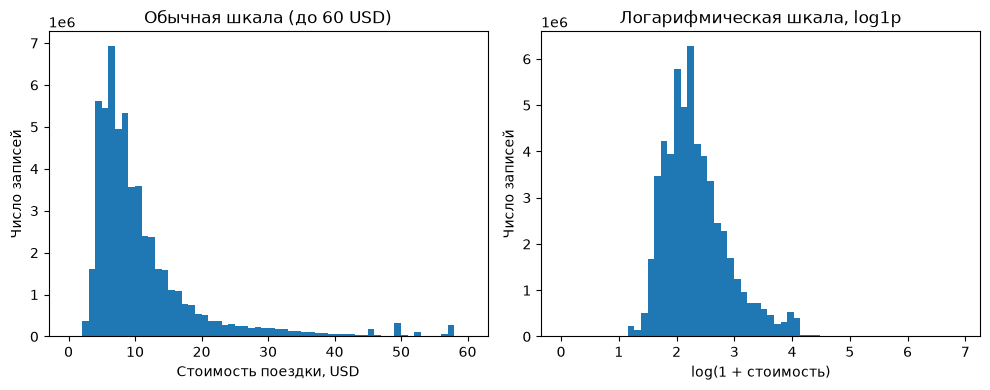

Записей выше 60 USD (не показаны на левой панели): 147 158


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

c1, e1 = np.histogram(x, bins=60, range=(0, 60))
axes[0].stairs(c1, e1, fill=True)
axes[0].set_xlabel("Стоимость поездки, USD")
axes[0].set_ylabel("Число записей")
axes[0].set_title("Обычная шкала (до 60 USD)")

c2, e2 = np.histogram(x_log, bins=60)
axes[1].stairs(c2, e2, fill=True)
axes[1].set_xlabel("log(1 + стоимость)")
axes[1].set_ylabel("Число записей")
axes[1].set_title("Логарифмическая шкала, log1p")

fig.tight_layout()
fig.savefig("../plots/stats_01_hist_scales.png", dpi=150)
plt.show()

print("Записей выше 60 USD (не показаны на левой панели):", f"{int((x > 60).sum()):,}".replace(",", " "))

In [8]:
res = stats.bootstrap_median_ci(x, n_boot=2000, sample_size=50_000, random_state=42)
boot = res["boot"]

print(f"Медиана выборки: {res['median_sample']:.4f}")
print(f"95% бутстрап-интервал: [{res['ci_low']:.4f}; {res['ci_high']:.4f}]")
print(f"Число повторов: {res['n_boot']}")
print("Доля повторов, совпавших с медианой выборки:", round(float(np.mean(boot == res['median_sample'])), 3))

Медиана выборки: 8.5000
95% бутстрап-интервал: [8.5000; 8.5000]
Число повторов: 2000
Доля повторов, совпавших с медианой выборки: 1.0


Гипотеза 1 (Манна–Уитни; из вывода работы 2 о росте стоимости со временем).
H0: распределение стоимости поездки (fare_amount) в 2010 и 2014 годах одинаково.
H1: распределения различаются.
Уровень значимости α = 0,05. Величина, важная для предметной области: разность медиан не менее 0,5 USD.
Размер эффекта: разность медиан (2014 − 2010) с 95 % бутстрап-интервалом и rank-biserial r. Выборка: по 50 000 записей за каждый год, random_state = 42.

Гипотеза 2 (Краскела–Уоллиса, попарные Манна–Уитни с поправкой Холма).
H0: распределение стоимости поездки одинаково во всех группах по числу пассажиров (1–6).
H1: распределения различаются хотя бы для одной пары групп.
Уровень значимости α = 0,05; попарные сравнения с поправкой Холма. Величина, важная для предметной области: разность медиан не менее 0,5 USD.
Размер эффекта: eta² для теста Краскела–Уоллиса; для пар, значимых после поправки, разность медиан с бутстрап-интервалом. Группа 0 и редкие группы (менее 1 % записей) в сравнение не входят.

Гипотеза 3 (z-тест для двух долей).
Событие: повышение тарифов на такси в Нью-Йорке, вступившее в силу 4 сентября 2012 г. (по данным TLC).
Сравниваемые периоды: до события (1 января 2009 – 3 сентября 2012) и после события (4 сентября 2012 – 1 июля 2015).
H0: доля поездок стоимостью более 10 USD одинакова до и после события.
H1: доли различаются.
Уровень значимости α = 0,05. Величина, важная для предметной области: разность долей не менее 2 п.п.
Размер эффекта: разность долей в процентных пунктах и h Кохена.

In [9]:
import sys
import importlib
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.append("../src")
import stats
importlib.reload(stats)

df = pd.read_parquet(
    "E:/laba_results/clean_final.parquet",
    columns=["fare_amount", "pickup_datetime", "passenger_count"],
)
df["year"] = df["pickup_datetime"].dt.year

In [10]:
a = df.loc[df["year"] == 2010, "fare_amount"].sample(n=50_000, random_state=42).to_numpy()
b = df.loc[df["year"] == 2014, "fare_amount"].sample(n=50_000, random_state=42).to_numpy()

u1, p1, r1 = stats.compare_two(a, b)
print(f"Медиана 2010: {np.median(a):.2f}, медиана 2014: {np.median(b):.2f}")
print(f"U = {u1:.0f}, p = {p1:.3g}, rank-biserial r = {r1:.3f}")

Медиана 2010: 7.70, медиана 2014: 9.50
U = 992552971, p = 0, rank-biserial r = -0.206


In [11]:
groups = {
    g: df.loc[df["passenger_count"] == g, "fare_amount"]
           .sample(n=20_000, random_state=42).to_numpy()
    for g in [1, 2, 3, 4, 5, 6]
}

h2, p2, eta2 = stats.kruskal_eta2(list(groups.values()))
print(f"Краскел–Уоллис: H = {h2:.1f}, p = {p2:.3g}, eta² = {eta2:.4f}")

pairs = stats.pairwise_holm(groups)
table_pairs = pd.DataFrame(pairs, columns=["Группа A", "Группа B", "p", "p Холма", "r"])
display(table_pairs.round(4))

n_sig = int((table_pairs["p Холма"] < 0.05).sum())
print(f"Пар, значимых после поправки Холма: {n_sig} из {len(pairs)}")

Краскел–Уоллис: H = 217.9, p = 4.27e-45, eta² = 0.0018


,Группа A,Группа B,p,p Холма,r
0,1,2,0.0000,0.0000,-0.0357
1,1,3,0.0000,0.0000,-0.0360
2,1,4,0.0000,0.0000,-0.0521
3,1,5,0.7442,1.0000,-0.0019
4,1,6,0.0000,0.0000,-0.0675
5,2,3,0.9746,1.0000,0.0002
6,2,4,0.0054,0.0227,-0.0160
7,2,5,0.0000,0.0000,0.0339
8,2,6,0.0000,0.0000,-0.0314
9,3,4,0.0045,0.0227,-0.0164


Пар, значимых после поправки Холма: 13 из 15


In [12]:
event = pd.Timestamp("2012-09-04")
before = df["pickup_datetime"] < event
expensive = df["fare_amount"] > 10

n1, k1 = int(before.sum()), int((before & expensive).sum())
n2, k2 = int((~before).sum()), int((~before & expensive).sum())

z3, p3, h3, s1, s2 = stats.share_ztest(k1, n1, k2, n2)
print(f"Доля >10 USD: до = {s1:.4f}, после = {s2:.4f}, разность = {100*(s2-s1):.2f} п.п.")
print(f"z = {z3:.2f}, p = {p3:.3g}, h Кохена = {h3:.3f}")
print(f"Записей: до = {n1:,}, после = {n2:,}".replace(",", " "))

Доля >10 USD: до = 0.3278, после = 0.4393, разность = 11.16 п.п.
z = -848.01, p = 0, h Кохена = -0.230
Записей: до = 31 834 568  после = 23 584 077


In [13]:
importlib.reload(stats)

d1, lo1, hi1 = stats.bootstrap_median_diff(a, b)
print(f"Гипотеза 1: разность медиан 2014−2010 = {d1:.2f} USD, 95% ДИ [{lo1:.2f}; {hi1:.2f}]")

rows = []
for g1, g2, p, ph, r in stats.pairwise_holm(groups):
    if ph < 0.05:
        d, lo, hi = stats.bootstrap_median_diff(groups[g1], groups[g2], n_boot=1000)
        rows.append((g1, g2, round(ph, 4), d, lo, hi))
display(pd.DataFrame(rows, columns=["A", "B", "p Холма", "Разность медиан B−A", "ДИ низ", "ДИ верх"]))

Гипотеза 1: разность медиан 2014−2010 = 1.80 USD, 95% ДИ [1.80; 1.80]


,A,B,p Холма,Разность медиан B−A,ДИ низ,ДИ верх
0,1,2,0.0000,0.0,0.0,0.4
1,1,3,0.0000,0.0,0.0,0.4
2,1,4,0.0000,0.0,0.0,0.8
3,1,6,0.0000,0.5,0.4,0.9
4,2,4,0.0227,0.0,0.0,0.4
5,2,5,0.0000,0.0,-0.4,0.0
6,2,6,0.0000,0.5,0.4,0.5
7,3,4,0.0227,0.0,0.0,0.4
8,3,5,0.0000,0.0,-0.4,0.0
9,3,6,0.0000,0.5,0.4,0.5


In [4]:
import gc
import shutil
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

PATH = "E:/laba_results/clean_final.parquet"
RANK_DIR = Path("E:/laba_results/tmp_ranks")
PLOTS = Path("..") / "plots"
PLOTS.mkdir(parents=True, exist_ok=True)

num_cols = ["fare_amount", "pickup_longitude", "pickup_latitude",
            "dropoff_longitude", "dropoff_latitude", "passenger_count"]
k = len(num_cols)
BATCH = 1_000_000
CHUNK = 2_000_000

pf = pq.ParquetFile(PATH)
n_total = pf.metadata.num_rows


def iter_raw(cols):
    """Блоки строк (m × len(cols)) в float64, читаются по BATCH строк."""
    for batch in pf.iter_batches(batch_size=BATCH, columns=cols):
        idx = {nm: j for j, nm in enumerate(batch.schema.names)}
        yield np.column_stack([
            batch.column(idx[c]).to_numpy(zero_copy_only=False).astype(np.float64)
            for c in cols
        ])


def iter_valid(cols):
    """То же, но только строки без пропусков (по маске valid)."""
    off = 0
    for X in iter_raw(cols):
        m = len(X)
        yield X[valid[off:off + m]]
        off += m


def pearson_from_blocks(blocks):
    """Пирсон по блокам (объединение средних и сумм произведений по Чану)."""
    n = 0
    mean = np.zeros(k)
    M2 = np.zeros((k, k))
    for X in blocks:
        m = len(X)
        if m == 0:
            continue
        mb = X.mean(axis=0)
        Xc = X - mb
        delta = mb - mean
        tot = n + m
        M2 += Xc.T @ Xc + np.outer(delta, delta) * (n * m / tot)
        mean += delta * (m / tot)
        n = tot
    d = np.sqrt(np.diag(M2))
    return M2 / np.outer(d, d)


# 1. Маска строк без пропусков (около 55 МБ)
valid = np.ones(n_total, dtype=bool)
off = 0
for X in iter_raw(num_cols):
    m = len(X)
    valid[off:off + m] = ~np.isnan(X).any(axis=1)
    off += m
n_valid = int(valid.sum())
print(f"записей всего: {n_total}; без пропусков: {n_valid}; исключено: {n_total - n_valid}")

# 2. Пирсон по исходным значениям
pearson_arr = pearson_from_blocks(iter_valid(num_cols))

# 3. Проверка места на E: для рангов
free_gb = shutil.disk_usage("E:/").free / 1e9
need_gb = n_valid * 8 * k / 1e9
print(f"Свободно на E:: {free_gb:.1f} ГБ, нужно для рангов около {need_gb:.1f} ГБ")
if free_gb < need_gb + 0.5:
    raise RuntimeError("Мало места на диске E:. Освободите место и запустите ячейку снова.")

shutil.rmtree(RANK_DIR, ignore_errors=True)
RANK_DIR.mkdir(parents=True, exist_ok=True)


def column_ranks(name, i):
    """Средние ранги одного столбца по валидным строкам; результат пишется на E:."""
    x = np.empty(n_valid, dtype=np.float64)
    pos = off = 0
    for X in iter_raw([name]):
        m = len(X)
        v = X[valid[off:off + m], 0]
        x[pos:pos + len(v)] = v
        pos += len(v)
        off += m

    order = np.argsort(x)
    xs = x[order]
    del x

    new = np.empty(n_valid, dtype=bool)
    new[0] = True
    np.not_equal(xs[1:], xs[:-1], out=new[1:])
    del xs

    starts = np.flatnonzero(new)
    del new
    bounds = np.append(starts, n_valid)
    del starts
    counts = np.diff(bounds)
    avg = (bounds[:-1] + bounds[1:] + 1) / 2.0   # средний ранг группы равных значений
    del bounds
    ranks_sorted = np.repeat(avg, counts)
    del avg, counts

    ranks = np.empty(n_valid, dtype=np.float64)
    ranks[order] = ranks_sorted
    del order, ranks_sorted

    path = RANK_DIR / f"rank_{i}.dat"
    ranks.tofile(path)
    del ranks
    gc.collect()
    return path


rank_paths = []
for i, name in enumerate(num_cols):
    rank_paths.append(column_ranks(name, i))
    print("ранги посчитаны:", name)


def iter_rank_blocks():
    mms = [np.memmap(p, dtype=np.float64, mode="r", shape=(n_valid,)) for p in rank_paths]
    for s in range(0, n_valid, CHUNK):
        e = min(s + CHUNK, n_valid)
        yield np.column_stack([mm[s:e] for mm in mms])


# 4. Спирмен = Пирсон по рангам
spearman_arr = pearson_from_blocks(iter_rank_blocks())
gc.collect()
shutil.rmtree(RANK_DIR, ignore_errors=True)

pearson = pd.DataFrame(pearson_arr, index=num_cols, columns=num_cols)
spearman = pd.DataFrame(spearman_arr, index=num_cols, columns=num_cols)
diff = pearson - spearman

print("Пирсон:")
print(pearson.round(3))
print("Спирмен:")
print(spearman.round(3))

upper = diff.where(np.triu(np.ones(diff.shape, dtype=bool), k=1))
a, b = upper.stack().abs().idxmax()

p_ab = pearson.loc[a, b]
s_ab = spearman.loc[a, b]
d_ab = diff.loc[a, b]

print(f"Наибольшее расхождение: {a} — {b}")
print(f"Пирсон = {p_ab:.4f}")
print(f"Спирмен = {s_ab:.4f}")
print(f"Разность = {d_ab:.4f}")

записей всего: 55418645; без пропусков: 55418269; исключено: 376
Свободно на E:: 248.5 ГБ, нужно для рангов около 2.7 ГБ
ранги посчитаны: fare_amount
ранги посчитаны: pickup_longitude
ранги посчитаны: pickup_latitude
ранги посчитаны: dropoff_longitude
ранги посчитаны: dropoff_latitude
ранги посчитаны: passenger_count
Пирсон:
                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount              1.000             0.011           -0.010   
pickup_longitude         0.011             1.000           -0.979   
pickup_latitude         -0.010            -0.979            1.000   
dropoff_longitude        0.012             0.952           -0.940   
dropoff_latitude        -0.012            -0.940            0.961   
passenger_count          0.013             0.001           -0.003   

                   dropoff_longitude  dropoff_latitude  passenger_count  
fare_amount                    0.012            -0.012            0.013  
pickup_longitude               0.952     

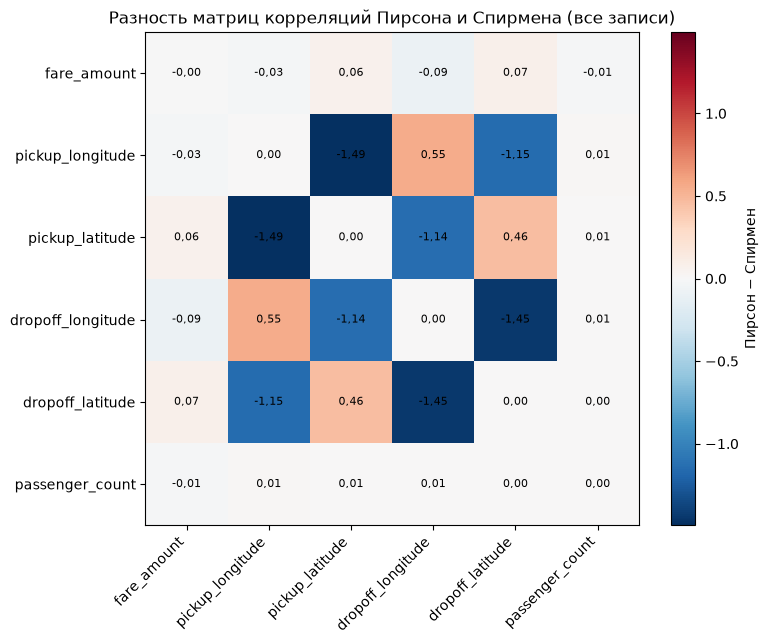

In [5]:
n = len(num_cols)
vmax = np.abs(diff.values).max()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(diff.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
ax.set_xticks(range(n)); ax.set_xticklabels(num_cols, rotation=45, ha="right")
ax.set_yticks(range(n)); ax.set_yticklabels(num_cols)
for i in range(n):
    for j in range(n):
        ax.text(j, i, f"{diff.values[i, j]:.2f}".replace(".", ","),
                ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Пирсон − Спирмен")
ax.set_title("Разность матриц корреляций Пирсона и Спирмена (все записи)")
fig.tight_layout()
fig.savefig(PLOTS / "corr_diff_heatmap.png", dpi=150)
plt.show()

Парадокс Симпсона. Пара: флаг — поездка с двумя и более пассажирами (`passenger_count ≥ 2`, только записи с 1–6 пассажирами); цель — `fare_amount`; столбец группы — год посадки. Сравниваем разность медиан тарифа (≥2 минус 1 пассажир) во всём наборе и внутри каждого года. Парадокс фиксируем, если общая разность и разности внутри групп имеют противоположные знаки. Если направление совпадает во всех годах, связь устойчива к разбиению по году; это тоже вывод.

Общая медиана: 1 пасс. = 8.50, ≥2 пасс. = 8.50, разность = +0.00 USD
      n, 1 пасс.  n, ≥2 пасс.  медиана, 1 пасс.  медиана, ≥2 пасс.  разность
год                                                                         
2009     5799677      2738667               7.7                7.7       0.0
2010     5715059      2637772               7.7                7.7       0.0
2011     5993361      2717766               7.7                8.1       0.4
2012     6187561      2666428               8.1                8.5       0.4
2013     6096070      2558373               9.0                9.5       0.5
2014     5813120      2441618               9.5                9.5       0.0
2015     2729185      1128458               9.5                9.5       0.0


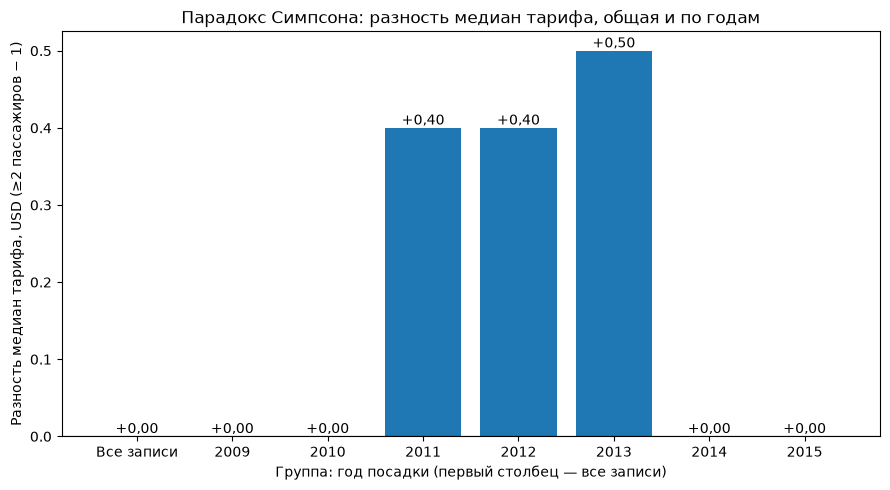

In [3]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from pathlib import Path
import matplotlib.pyplot as plt

PATH = "E:/laba_results/clean_final.parquet"
PLOTS = Path("..") / "plots"
PLOTS.mkdir(parents=True, exist_ok=True)

YEARS = list(range(2009, 2016))
CENT_MAX = 100_000  # 1000 USD в центах; выше обрезается, на медиану не влияет

# гистограмма тарифа в центах: [год, флаг (0 = один пассажир, 1 = два и больше)]
hist = np.zeros((len(YEARS), 2, CENT_MAX + 1), dtype=np.int64)

pf = pq.ParquetFile(PATH)
for batch in pf.iter_batches(batch_size=1_000_000,
                             columns=["fare_amount", "passenger_count", "pickup_datetime"]):
    idx = {nm: j for j, nm in enumerate(batch.schema.names)}
    fare = batch.column(idx["fare_amount"]).to_numpy(zero_copy_only=False).astype(np.float64)
    pc = batch.column(idx["passenger_count"]).to_numpy(zero_copy_only=False).astype(np.float64)
    ts = batch.column(idx["pickup_datetime"]).to_numpy(zero_copy_only=False)

    ok = ~np.isnan(fare) & ~np.isnan(pc) & (pc >= 1) & (pc <= 6) & ~np.isnat(ts)
    year = ts.astype("datetime64[Y]").astype(np.int64) + 1970
    flag = (pc >= 2).astype(np.int64)
    cents = np.clip(np.rint(np.nan_to_num(fare) * 100), 0, CENT_MAX).astype(np.int64)

    for yi, y in enumerate(YEARS):
        in_year = ok & (year == y)
        for f in (0, 1):
            m = in_year & (flag == f)
            if m.any():
                hist[yi, f] += np.bincount(cents[m], minlength=CENT_MAX + 1)


def median_from_hist(h):
    n = h.sum()
    if n == 0:
        return np.nan
    cdf = np.cumsum(h)
    lo, hi = (n - 1) // 2, n // 2
    v_lo = np.searchsorted(cdf, lo, side="right")
    v_hi = np.searchsorted(cdf, hi, side="right")
    return (v_lo + v_hi) / 2 / 100


overall_hist = hist.sum(axis=0)
med_all = {f: median_from_hist(overall_hist[f]) for f in (0, 1)}
overall_diff = med_all[1] - med_all[0]

rows = []
for yi, y in enumerate(YEARS):
    m0 = median_from_hist(hist[yi, 0])
    m1 = median_from_hist(hist[yi, 1])
    rows.append({"год": y,
                 "n, 1 пасс.": int(hist[yi, 0].sum()),
                 "n, ≥2 пасс.": int(hist[yi, 1].sum()),
                 "медиана, 1 пасс.": m0,
                 "медиана, ≥2 пасс.": m1,
                 "разность": m1 - m0})
res = pd.DataFrame(rows).set_index("год")

print(f"Общая медиана: 1 пасс. = {med_all[0]:.2f}, ≥2 пасс. = {med_all[1]:.2f}, "
      f"разность = {overall_diff:+.2f} USD")
print(res.round(2).to_string())

labels = ["Все записи"] + [str(y) for y in YEARS]
values = [overall_diff] + list(res["разность"])
colors = ["tab:gray"] + ["tab:blue" if v >= 0 else "tab:red" for v in res["разность"]]

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(labels, values, color=colors)
ax.axhline(0, color="black", lw=0.8)
for x, v in enumerate(values):
    ax.text(x, v, f"{v:+.2f}".replace(".", ","), ha="center",
            va="bottom" if v >= 0 else "top")
ax.set_xlabel("Группа: год посадки (первый столбец — все записи)")
ax.set_ylabel("Разность медиан тарифа, USD (≥2 пассажиров − 1)")
ax.set_title("Парадокс Симпсона: разность медиан тарифа, общая и по годам")
fig.tight_layout()
fig.savefig(PLOTS / "simpson_diff.png", dpi=150)
plt.show()